In [2]:
# Phase 1: Scalable Data Aggregation & Exploratory Data Analysis
# Project: UrbanFlow - Predictive Analytics for Smart City Mobility
## Objective:** Process 12 months of raw NYC TLC Parquet files (~50 million rows) without exceeding local memory limits. We will aggregate the data into an hourly demand matrix and perform initial EDA to understand temporal and spatial patterns.

In [3]:
!pip install duckdb

In [5]:
!pip install --force-reinstall --no-cache-dir "numpy==1.26.4" matplotlib contourpy

  Obtaining dependency information for numpy==1.26.4 from https://files.pythonhosted.org/packages/3f/6b/5610004206cf7f8e7ad91c5a85a8c71b2f2f8051a0c0c4d5916b76d6cbb2/numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata
     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     -------------------- ------------------- 30.7/61.0 kB ? eta -:--:--
     -------------------- ------------------- 30.7/61.0 kB ? eta -:--:--
     -------------------------------------- 61.0/61.0 kB 540.4 kB/s eta 0:00:00
  Obtaining dependency information for matplotlib from https://files.pythonhosted.org/packages/66/54/91fe3fdfa29100b4668cbf9721577a10acde6e009694618230e4e7a97527/matplotlib-3.11.2-cp311-cp311-win_amd64.whl.metadata
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 80.3/80.3 kB ? eta 0:00:00
  Obtaining dependency information for contourpy from https://files.pythonhosted.org/packages/98/4b/9bd370b004b5c9d8045c6c33cf65b

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
conda-repo-cli 1.0.75 requires requests_mock, which is not installed.
gensim 4.3.0 requires FuzzyTM>=0.4.0, which is not installed.
tables 3.8.0 requires blosc2~=2.0.0, which is not installed.
tables 3.8.0 requires cython>=0.29.21, which is not installed.
shap 0.51.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
conda-repo-cli 1.0.75 requires clyent==1.2.1, but you have clyent 1.2.2 which is incompatible.
conda-repo-cli 1.0.75 requires python-dateutil==2.8.2, but you have python-dateutil 2.9.0.post0 which is incompatible.
conda-repo-cli 1.0.75 requires PyYAML==6.0.1, but you have pyyaml 6.0 which is incompatible.
ortools 9.14.6206 requires protobuf<6.32,>=6.31.1, but you have protobuf 3.20.3 which is incompatible.
python-lsp-black 1.2.1 requires black>=22.3.0, but you have black 0.0 which is 

In [3]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import warnings

# Suppress version warnings for a clean output
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option('display.max_columns', None)

# Print versions to verify the fix worked
print(f"NumPy version: {np.__version__}")
print(f" Matplotlib version: {plt.matplotlib.__version__}")
print(" Environment initialized successfully. All libraries loaded.")

NumPy version: 1.26.4
 Matplotlib version: 3.11.2
 Environment initialized successfully. All libraries loaded.


In [4]:
project_folder = r"C:\Users\Harshitha\Downloads\Project spy"
parquet_pattern = os.path.join(project_folder, "yellow_tripdata_2024-*.parquet")

# Verify dataset completeness
files = sorted(glob.glob(parquet_pattern))
print(f" Directory: {project_folder}")
print(f" Found {len(files)} Parquet files:\n")
for f in files:
    size_mb = os.path.getsize(f) / (1024 * 1024)
    print(f"   • {os.path.basename(f)} ({size_mb:.1f} MB)")

 Directory: C:\Users\Harshitha\Downloads\Project spy
 Found 12 Parquet files:

   • yellow_tripdata_2024-01.parquet (47.6 MB)
   • yellow_tripdata_2024-02.parquet (48.0 MB)
   • yellow_tripdata_2024-03.parquet (57.3 MB)
   • yellow_tripdata_2024-04.parquet (56.4 MB)
   • yellow_tripdata_2024-05.parquet (59.7 MB)
   • yellow_tripdata_2024-06.parquet (57.1 MB)
   • yellow_tripdata_2024-07.parquet (49.9 MB)
   • yellow_tripdata_2024-08.parquet (48.7 MB)
   • yellow_tripdata_2024-09.parquet (58.3 MB)
   • yellow_tripdata_2024-10.parquet (61.4 MB)
   • yellow_tripdata_2024-11.parquet (57.8 MB)
   • yellow_tripdata_2024-12.parquet (58.7 MB)


In [5]:
# Connect to DuckDB for in-process OLAP processing
con = duckdb.connect()

# SQL Query: Filter anomalies and aggregate by hour and zone
query = f"""
    SELECT 
        date_trunc('hour', tpep_pickup_datetime) AS pickup_hour,
        PULocationID AS zone_id,
        COUNT(*) AS demand_count
    FROM read_parquet('{parquet_pattern}')
    WHERE 
        fare_amount > 0 
        AND trip_distance > 0 
        AND passenger_count > 0
        AND tpep_pickup_datetime >= '2024-01-01'
        AND tpep_pickup_datetime < '2025-01-01'
    GROUP BY 1, 2
    ORDER BY 1, 2
"""

print(" Executing DuckDB SQL query (processing 50M rows)...")
demand_df = con.execute(query).df()

print(f"\n Aggregation Complete!")
print(f"   • Raw rows processed: ~50,000,000")
print(f"   • Aggregated rows:    {len(demand_df):,}")
print(f"   • Compression ratio:  {50_000_000 / len(demand_df):.0f}x")
print(demand_df.head())

 Executing DuckDB SQL query (processing 50M rows)...

 Aggregation Complete!
   • Raw rows processed: ~50,000,000
   • Aggregated rows:    882,206
   • Compression ratio:  57x
  pickup_hour  zone_id  demand_count
0  2024-01-01        4            20
1  2024-01-01        7             1
2  2024-01-01       12             3
3  2024-01-01       13            11
4  2024-01-01       14             1


In [6]:
output_path = os.path.join(project_folder, "aggregated_demand_2024.parquet")
demand_df.to_parquet(output_path, index=False)

print(f" Saved clean dataset to: {output_path}")
print(f"   File size: {os.path.getsize(output_path) / (1024*1024):.1f} MB")

 Saved clean dataset to: C:\Users\Harshitha\Downloads\Project spy\aggregated_demand_2024.parquet
   File size: 1.7 MB


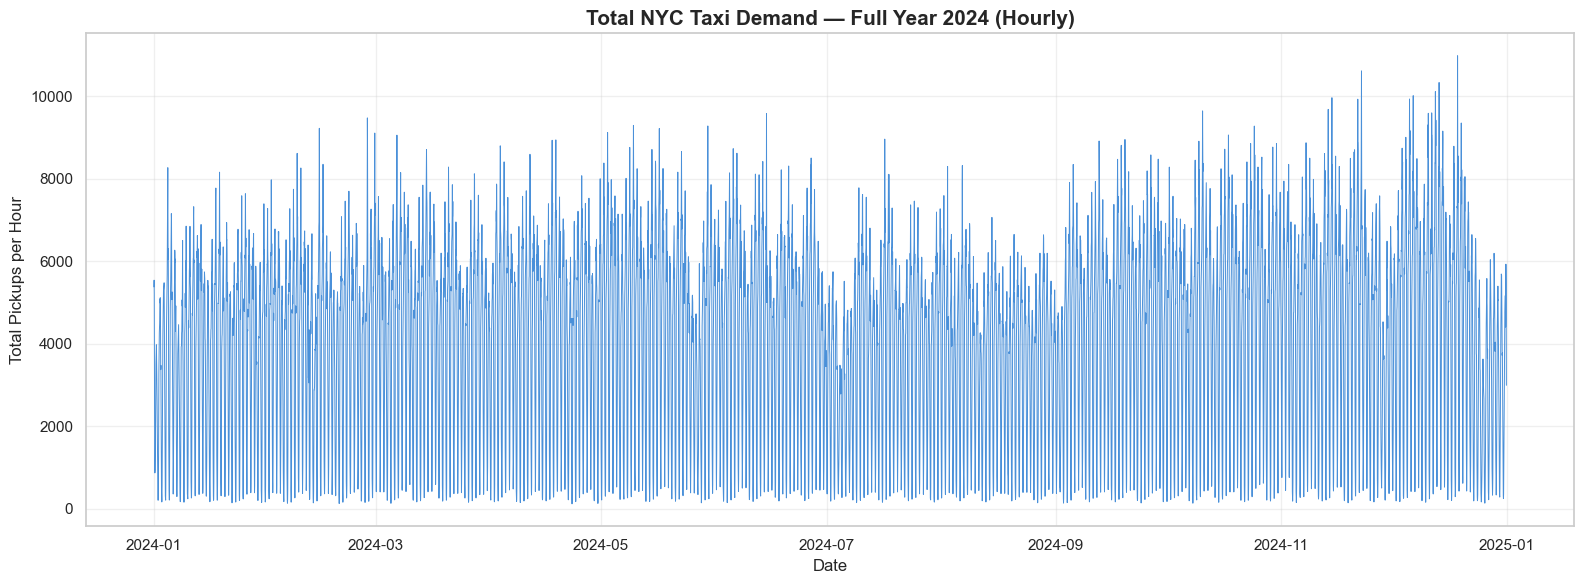

In [17]:
plt.figure(figsize=(16, 6))

hourly_trend = demand_df.groupby('pickup_hour')['demand_count'].sum()
plt.plot(hourly_trend.index, hourly_trend.values, color='#4A90D9', linewidth=0.7)

plt.title('Total NYC Taxi Demand — Full Year 2024 (Hourly)', fontsize=15, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Pickups per Hour', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(project_folder, "week1_demand_timeseries.png"), dpi=150)
plt.show()

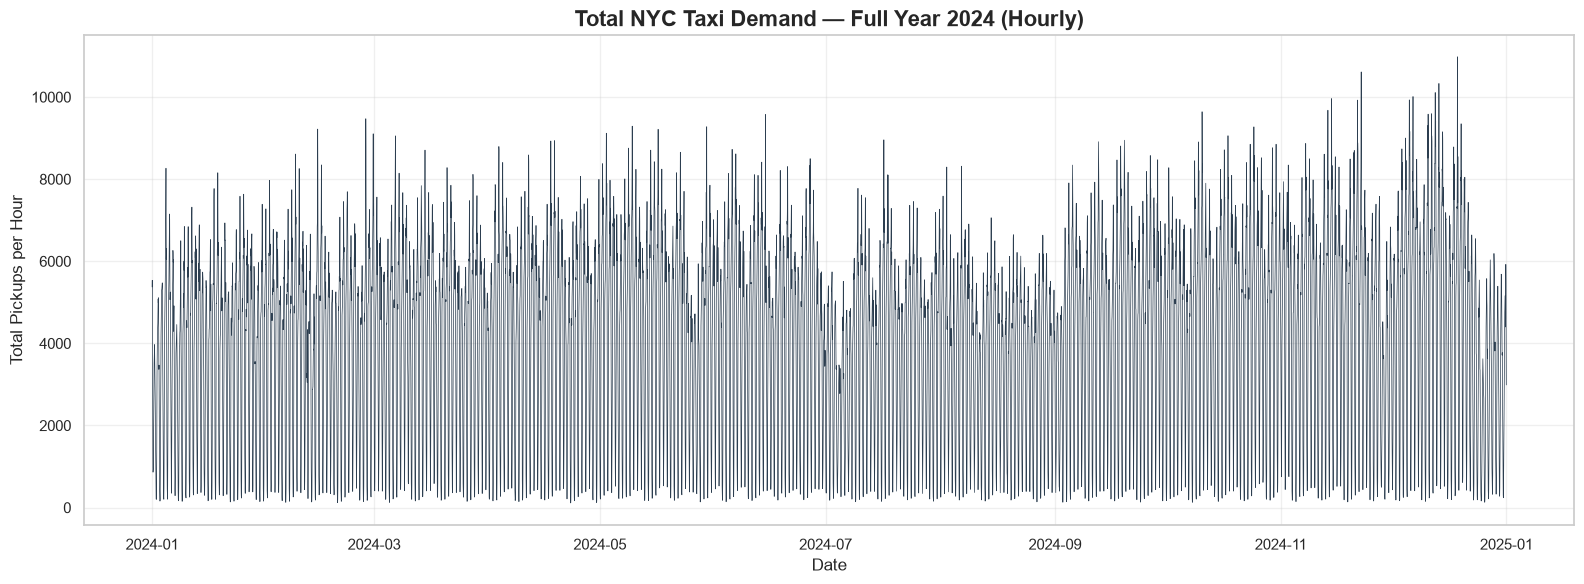

  Distinct seasonal trends and daily cyclicality are visible.


In [7]:
plt.figure(figsize=(16, 6))
hourly_trend = demand_df.groupby('pickup_hour')['demand_count'].sum()
plt.plot(hourly_trend.index, hourly_trend.values, color='#2C3E50', linewidth=0.5)

plt.title('Total NYC Taxi Demand — Full Year 2024 (Hourly)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Pickups per Hour', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(project_folder, "week1_demand_timeseries.png"), dpi=150)
plt.show()

print("  Distinct seasonal trends and daily cyclicality are visible.")

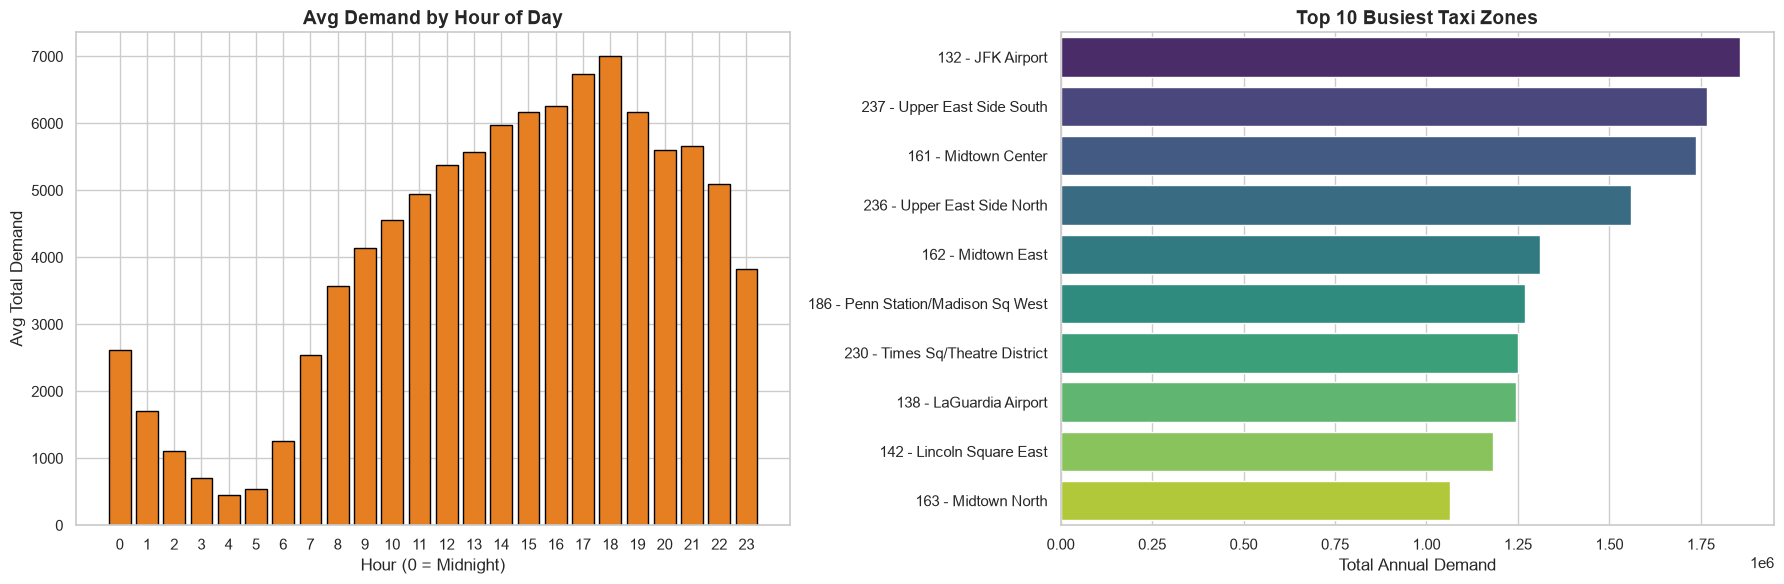

 Demand peaks at 6 PM (18:00). JFK Airport and Midtown Center are the highest volume zones.


In [8]:
# 1. Hourly Pattern
demand_df['hour_of_day'] = pd.to_datetime(demand_df['pickup_hour']).dt.hour
hourly_avg = demand_df.groupby('hour_of_day')['demand_count'].sum() / 365

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].bar(hourly_avg.index, hourly_avg.values, color='#E67E22', edgecolor='black')
axes[0].set_title('Avg Demand by Hour of Day', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hour (0 = Midnight)')
axes[0].set_ylabel('Avg Total Demand')
axes[0].set_xticks(range(0, 24))

# 2. Spatial EDA (Merging Zone Names)
zone_lookup = pd.read_csv(os.path.join(project_folder, "taxi_zone_lookup.csv"))
top_zones = demand_df.groupby('zone_id')['demand_count'].sum().sort_values(ascending=False).head(10).reset_index()
top_zones = top_zones.merge(zone_lookup, left_on='zone_id', right_on='LocationID', how='left')
top_zones['zone_label'] = top_zones['zone_id'].astype(str) + " - " + top_zones['Zone']

sns.barplot(data=top_zones, y='zone_label', x='demand_count', ax=axes[1], palette="viridis")
axes[1].set_title('Top 10 Busiest Taxi Zones', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Annual Demand')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig(os.path.join(project_folder, "week1_eda_combined.png"), dpi=150)
plt.show()

print(" Demand peaks at 6 PM (18:00). JFK Airport and Midtown Center are the highest volume zones.")